# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Intifada Afkar Lazain Muhammad | 5054251029 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
N_INIT = 10

In [2]:
df = pd.read_csv("Live.csv")

print("Jumlah baris, kolom:", df.shape)
print("\n=== Info ===")
df.info()

print("\n=== Statistik deskriptif ===")
display(df.describe(include="all").T)

print("\n=== Missing value per kolom ===")
display(df.isna().sum().to_frame("missing"))

print("Baris duplikat (seluruh kolom):", df.duplicated().sum())
print("status_id duplikat:", df["status_id"].duplicated().sum())

empty_cols = df.columns[df.isna().all()].tolist()
print("Kolom yang seluruhnya kosong:", empty_cols)

Jumlah baris, kolom: (7050, 16)

=== Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   object 
 2   status_published  7050 non-null   object 
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
d

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
status_id,7050.0,NaN,NaN,NaN,3525.5,2035.304031,1.0,1763.25,3525.5,5287.75,7050.0
status_type,7050,4,photo,4288,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status_published,7050,6913,3/20/2018 1:54,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_reactions,7050.0,NaN,NaN,NaN,230.117163,462.625309,0.0,17.0,59.5,219.0,4710.0
num_comments,7050.0,NaN,NaN,NaN,224.356028,889.63682,0.0,0.0,4.0,23.0,20990.0
num_shares,7050.0,NaN,NaN,NaN,40.022553,131.599965,0.0,0.0,0.0,4.0,3424.0
num_likes,7050.0,NaN,NaN,NaN,215.043121,449.472357,0.0,17.0,58.0,184.75,4710.0
num_loves,7050.0,NaN,NaN,NaN,12.728652,39.97293,0.0,0.0,0.0,3.0,657.0
num_wows,7050.0,NaN,NaN,NaN,1.289362,8.71965,0.0,0.0,0.0,0.0,278.0
num_hahas,7050.0,NaN,NaN,NaN,0.696454,3.957183,0.0,0.0,0.0,0.0,157.0



=== Missing value per kolom ===


,missing
status_id,0
status_type,0
status_published,0
num_reactions,0
num_comments,0
num_shares,0
num_likes,0
num_loves,0
num_wows,0
num_hahas,0


Baris duplikat (seluruh kolom): 0
status_id duplikat: 0
Kolom yang seluruhnya kosong: ['Column1', 'Column2', 'Column3', 'Column4']


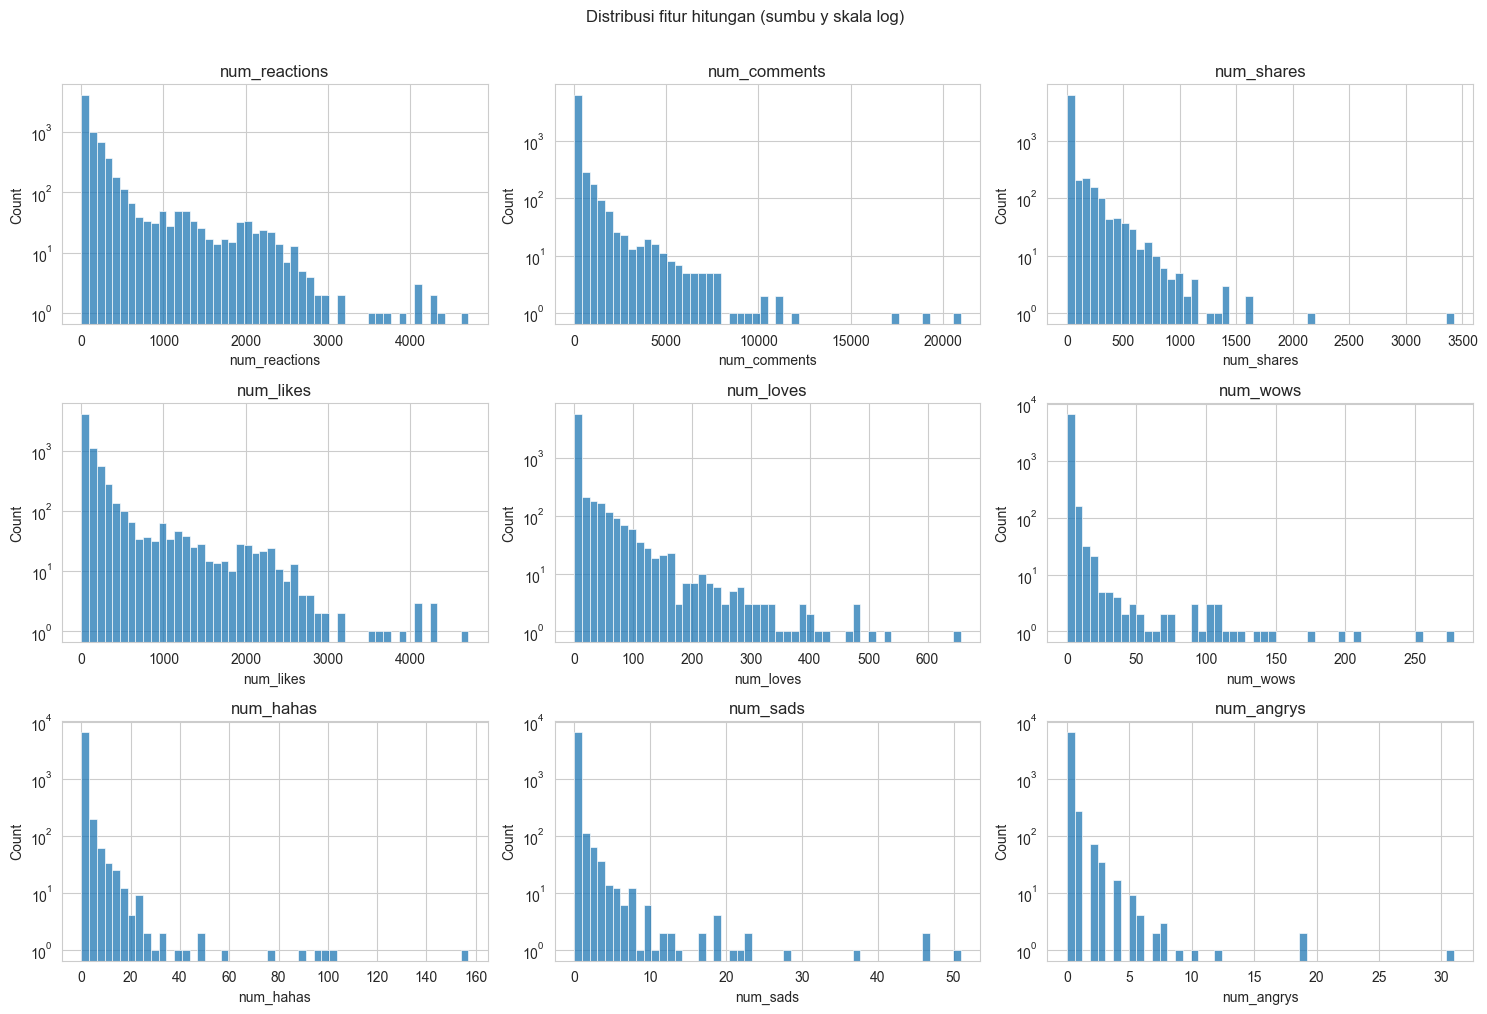

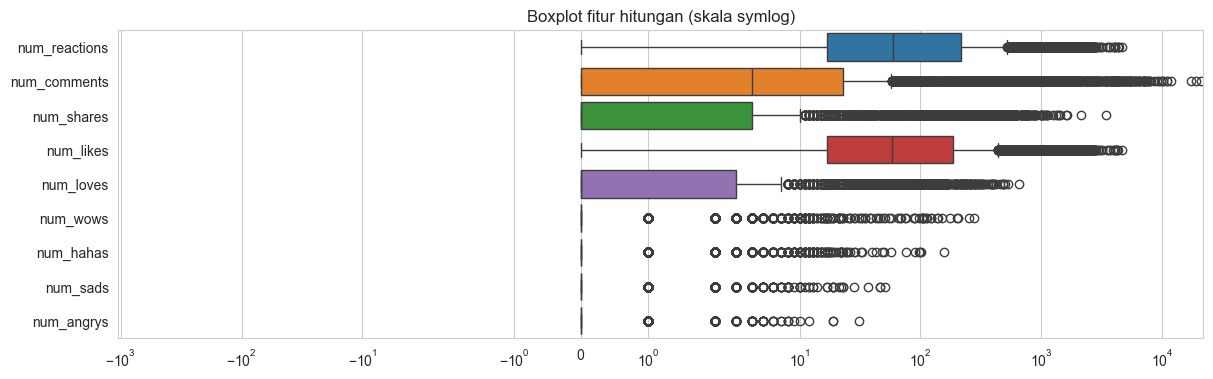

,skewness,proporsi_nol,median,max
num_reactions,3.738,0.017,59.5,4710
num_comments,9.029,0.301,4.0,20990
num_shares,7.099,0.555,0.0,3424
num_likes,3.919,0.018,58.0,4710
num_loves,6.005,0.600,0.0,657
num_wows,18.247,0.753,0.0,278
num_hahas,20.306,0.839,0.0,157
num_sads,17.579,0.914,0.0,51
num_angrys,19.507,0.940,0.0,31


In [3]:
count_cols = ["num_reactions", "num_comments", "num_shares", "num_likes",
              "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), count_cols):
    sns.histplot(df[c], bins=50, ax=ax)
    ax.set_yscale("log")
    ax.set_title(c)
plt.suptitle("Distribusi fitur hitungan (sumbu y skala log)", y=1.01)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
sns.boxplot(data=df[count_cols], ax=ax, orient="h")
ax.set_xscale("symlog")
ax.set_title("Boxplot fitur hitungan (skala symlog)")
plt.show()

summary = pd.DataFrame({
    "skewness": df[count_cols].skew(),
    "proporsi_nol": (df[count_cols] == 0).mean(),
    "median": df[count_cols].median(),
    "max": df[count_cols].max(),
})
display(summary.round(3))

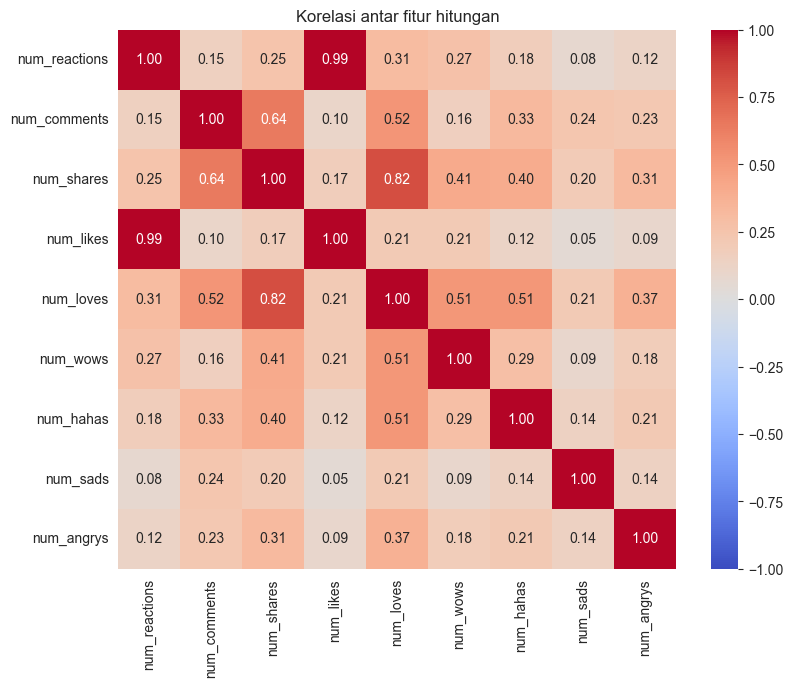

num_reactions == jumlah semua reaksi pada 99.87234042553192 % baris

Pasangan fitur dengan korelasi tertinggi:


korelasi
num_reactions num_likes   0.994923
num_shares    num_loves   0.820000
num_comments  num_shares  0.640637
              num_loves   0.521223
num_loves     num_wows    0.508798
              num_hahas   0.507830
num_shares    num_wows    0.407628
              num_hahas   0.399826

In [4]:
corr = df[count_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi antar fitur hitungan")
plt.show()

# Cek redundansi secara definisi: num_reactions = likes + loves + wows + hahas + sads + angrys ?
react_sum = df[["num_likes", "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]].sum(axis=1)
print("num_reactions == jumlah semua reaksi pada", (react_sum == df["num_reactions"]).mean() * 100, "% baris")

pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().sort_values(ascending=False))
print("\nPasangan fitur dengan korelasi tertinggi:")
display(pairs.head(8).to_frame("korelasi"))

,jumlah_posting,proporsi_emoji
status_published,,
2012,589,0.000
2013,500,0.000
2014,233,0.000
2015,337,0.000
2016,588,0.680
2017,2253,0.542
2018,2550,0.578


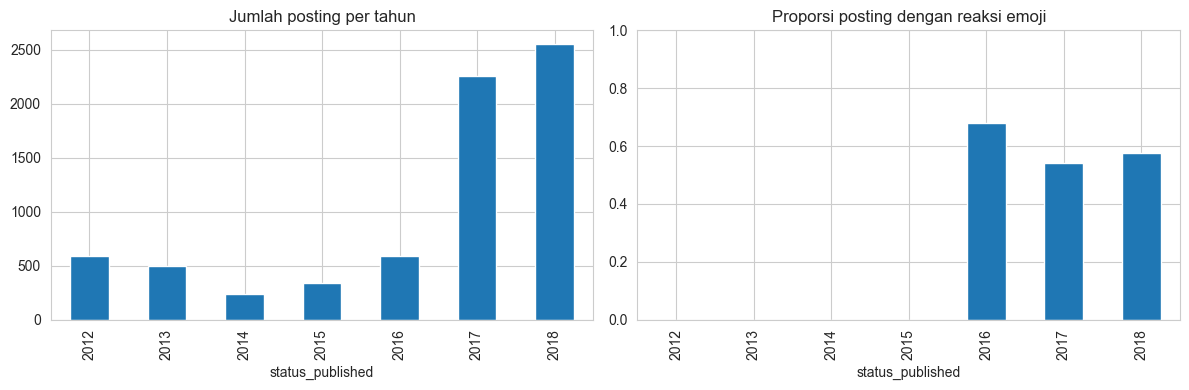

In [5]:
df["status_published"] = pd.to_datetime(df["status_published"])
emoji_cols = ["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
df["has_emoji"] = (df[emoji_cols].sum(axis=1) > 0)

yearly = df.groupby(df["status_published"].dt.year).agg(
    jumlah_posting=("status_id", "count"),
    proporsi_emoji=("has_emoji", "mean"),
)
display(yearly.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
yearly["jumlah_posting"].plot(kind="bar", ax=ax[0], title="Jumlah posting per tahun")
yearly["proporsi_emoji"].plot(kind="bar", ax=ax[1], title="Proporsi posting dengan reaksi emoji", ylim=(0, 1))
plt.tight_layout()
plt.show()

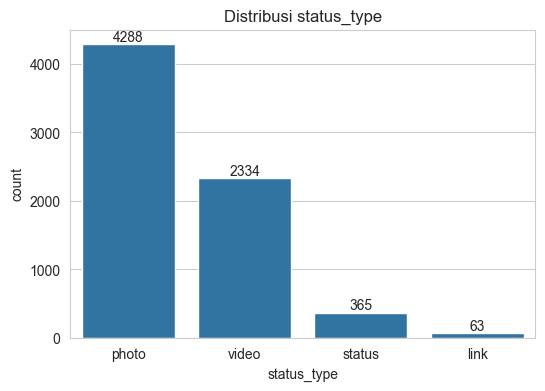

,num_likes,num_comments,num_shares
status_type,,,
link,48.0,1.0,0.0
photo,34.0,2.0,0.0
status,117.0,10.0,0.0
video,117.0,39.0,12.0


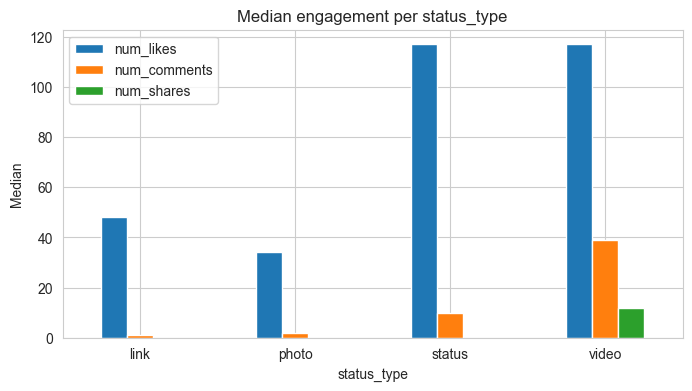

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="status_type", order=df["status_type"].value_counts().index, ax=ax)
ax.set_title("Distribusi status_type")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

med = df.groupby("status_type")[["num_likes", "num_comments", "num_shares"]].median()
display(med)
med.plot(kind="bar", figsize=(8, 4), title="Median engagement per status_type")
plt.ylabel("Median")
plt.xticks(rotation=0)
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

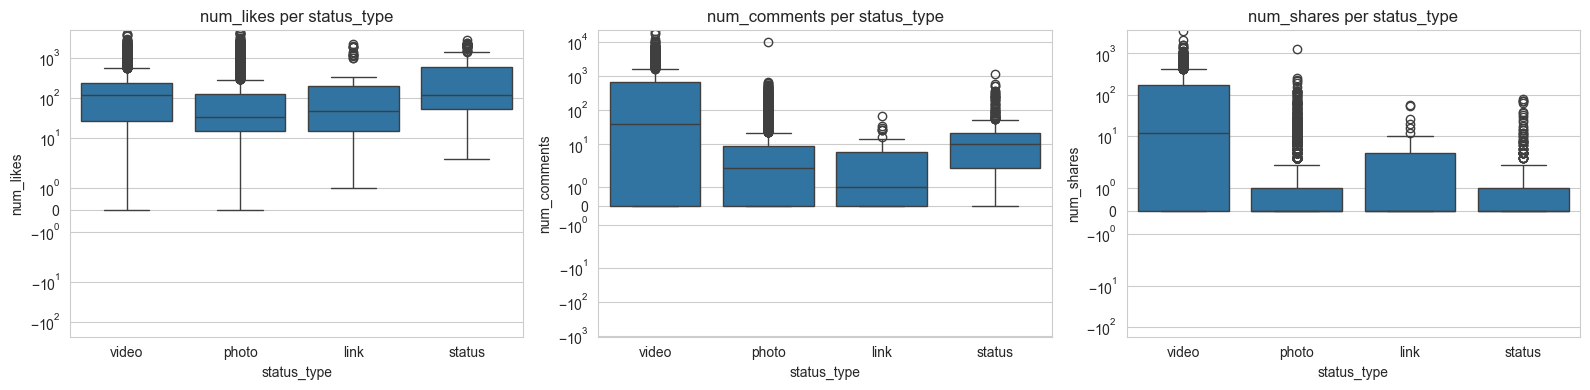

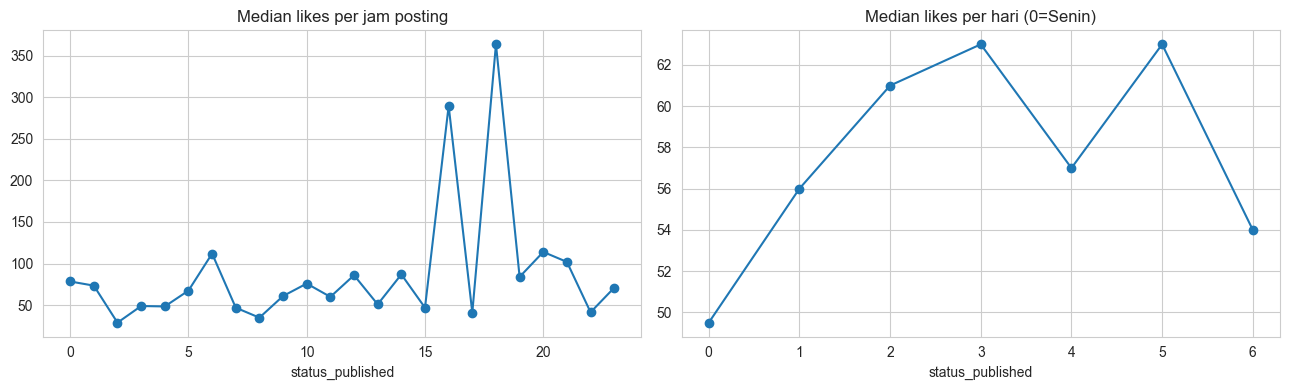

,proporsi_punya_emoji
status_type,
link,0.238
photo,0.365
status,0.504
video,0.570


In [7]:
# EDA tambahan 1: engagement per status_type (skala log) dan pola waktu posting
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["num_likes", "num_comments", "num_shares"]):
    sns.boxplot(data=df, x="status_type", y=c, ax=ax)
    ax.set_yscale("symlog")
    ax.set_title(f"{c} per status_type")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.groupby(df["status_published"].dt.hour)["num_likes"].median().plot(ax=axes[0], marker="o", title="Median likes per jam posting")
df.groupby(df["status_published"].dt.dayofweek)["num_likes"].median().plot(ax=axes[1], marker="o", title="Median likes per hari (0=Senin)")
plt.tight_layout()
plt.show()

# EDA tambahan 2: proporsi emoji per status_type
display(df.groupby("status_type")["has_emoji"].mean().round(3).to_frame("proporsi_punya_emoji"))

# 2. Preprocessing

In [8]:
# 1) Hapus kolom yang seluruhnya kosong
df = df.drop(columns=df.columns[df.isna().all()])

# 2) Duplikat (status_id seharusnya unik)
print("Duplikat baris penuh :", df.duplicated().sum())
print("Duplikat status_id   :", df["status_id"].duplicated().sum())
n_before = len(df)
df = df.drop_duplicates(subset="status_id", keep="first").reset_index(drop=True)
print(f"Baris: {n_before} -> {len(df)}")

# 3) Missing value
print("\nMissing value setelah pembersihan kolom:")
print(df.isna().sum().sum(), "sel kosong")

# 4) Outlier ekstrem (IQR + persentil)
num = ["num_likes", "num_comments", "num_shares"]
q = df[num].quantile([0.5, 0.95, 0.99, 1.0]).T
q["batas_IQR"] = df[num].quantile(0.75) + 3 * (df[num].quantile(0.75) - df[num].quantile(0.25))
q["n_di_atas_batas"] = [(df[c] > q.loc[c, "batas_IQR"]).sum() for c in num]
display(q)
# Keputusan: outlier TIDAK dibuang. Posting viral adalah perilaku nyata yang ingin ditemukan
# oleh clustering; dampaknya pada jarak diredam dengan transformasi log1p + scaling.

Duplikat baris penuh : 0
Duplikat status_id   : 0
Baris: 7050 -> 7050

Missing value setelah pembersihan kolom:
0 sel kosong


,0.5,0.95,0.99,1.0,batas_IQR,n_di_atas_batas
num_likes,58.0,1160.10,2297.00,4710.0,688.0,555
num_comments,4.0,1210.65,4338.04,20990.0,92.0,1250
num_shares,0.0,260.10,607.00,3424.0,16.0,1243


In [9]:
# Pisahkan kolom untuk interpretasi
meta = df[["status_id", "status_type", "status_published"]].copy()

# Redundansi: num_reactions = likes + loves + wows + hahas + sads + angrys
reaction_parts = ["num_likes", "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
print("num_reactions == jumlah reaksi:", (df[reaction_parts].sum(axis=1) == df["num_reactions"]).all())

# Proporsi nol tiap fitur
cand = ["num_likes", "num_comments", "num_shares", "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
display((df[cand] == 0).mean().round(3).to_frame("proporsi_nol"))

# Gabungkan emoji yang sparse menjadi satu fitur
df["num_emoji"] = df[["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]].sum(axis=1)
print("Proporsi nol num_emoji:", round((df["num_emoji"] == 0).mean(), 3))

features = ["num_likes", "num_comments", "num_shares", "num_emoji"]
X_raw = df[features].astype(float).copy()
print("\nBentuk X_raw:", X_raw.shape, "| semua numerik:", all(np.issubdtype(t, np.number) for t in X_raw.dtypes))
display(X_raw.describe().T)

num_reactions == jumlah reaksi: False


,proporsi_nol
num_likes,0.018
num_comments,0.301
num_shares,0.555
num_loves,0.600
num_wows,0.753
num_hahas,0.839
num_sads,0.914
num_angrys,0.940


Proporsi nol num_emoji: 0.561

Bentuk X_raw: (7050, 4) | semua numerik: True


,count,mean,std,min,25%,50%,75%,max
num_likes,7050.0,215.043121,449.472357,0.0,17.0,58.0,184.75,4710.0
num_comments,7050.0,224.356028,889.636820,0.0,0.0,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.0,0.0,4.00,3424.0
num_emoji,7050.0,15.071348,47.790540,0.0,0.0,0.0,6.00,886.0


Fitur yang dipilih untuk clustering: num_likes, num_comments, num_shares, dan num_emoji.

- num_reactions dibuang karena redundan: nilainya persis jumlah likes + loves + wows + hahas + sads + angrys, sehingga memasukkannya akan menghitung engagement yang sama dua kali dalam perhitungan jarak.
- Reaksi emoji (num_loves, num_wows, num_hahas, num_sads, num_angrys) sebagian besar bernilai nol (terutama posting sebelum emoji reactions diperkenalkan), sehingga masing-masing digabung menjadi satu fitur num_emoji. Dengan begitu fitur tidak sparse dan lima dimensi yang hampir seluruhnya nol tidak mendominasi jarak.
- status_id dibuang (identifier), sedangkan status_type dan status_published hanya disimpan untuk interpretasi cluster dan tidak dipakai sebagai fitur.

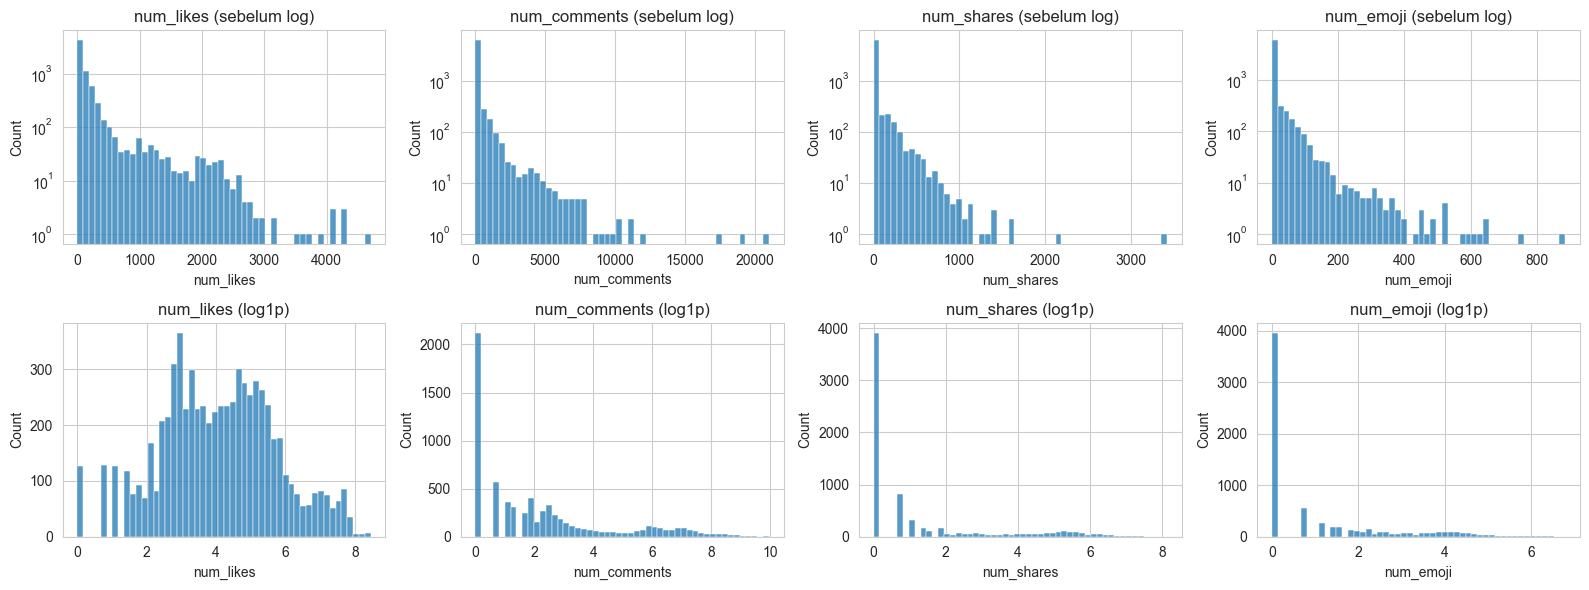

,skew_sebelum,skew_sesudah
num_likes,3.919,-0.014
num_comments,9.029,1.038
num_shares,7.099,1.526
num_emoji,6.990,1.289


In [10]:
X_log = np.log1p(X_raw)

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i, c in enumerate(features):
    sns.histplot(X_raw[c], bins=50, ax=axes[0, i])
    axes[0, i].set_title(f"{c} (sebelum log)")
    axes[0, i].set_yscale("log")
    sns.histplot(X_log[c], bins=50, ax=axes[1, i])
    axes[1, i].set_title(f"{c} (log1p)")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"skew_sebelum": X_raw.skew(), "skew_sesudah": X_log.skew()}).round(3))

In [11]:
# X_log_scaled: log1p + StandardScaler
X_log_scaled = StandardScaler().fit_transform(X_log)

# X_raw_scaled: mentah + scaling saja
X_raw_scaled = StandardScaler().fit_transform(X_raw)

# X_raw: mentah tanpa transformasi dan tanpa scaling (sudah dibuat di atas)
print("X_raw         :", X_raw.shape)
print("X_raw_scaled  :", X_raw_scaled.shape)
print("X_log_scaled  :", X_log_scaled.shape)
print("Mean/std X_log_scaled:", X_log_scaled.mean(axis=0).round(3), X_log_scaled.std(axis=0).round(3))

X_raw         : (7050, 4)
X_raw_scaled  : (7050, 4)
X_log_scaled  : (7050, 4)
Mean/std X_log_scaled: [-0.  0. -0.  0.] [1. 1. 1. 1.]


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [12]:
K_DEMO = 3
versions = {
    "X_raw (mentah)": X_raw.values,
    "X_raw_scaled": X_raw_scaled,
    "X_log_scaled": X_log_scaled,
}
labels_demo = {}
for name, X in versions.items():
    km = KMeans(n_clusters=K_DEMO, random_state=RANDOM_STATE, n_init=N_INIT)
    labels_demo[name] = km.fit_predict(X)
    print(f"{name:15s} selesai | inertia = {km.inertia_:,.1f}")

X_raw (mentah)  selesai | inertia = 2,391,224,209.9
X_raw_scaled    selesai | inertia = 11,920.1
X_log_scaled    selesai | inertia = 6,893.1


In [13]:
rows = []
for name, lab in labels_demo.items():
    sizes = pd.Series(lab).value_counts().sort_index().tolist()
    rows.append({
        "Versi data": name,
        "Ukuran cluster": sizes,
        "Cluster terkecil": min(sizes),
        "Cluster terbesar": max(sizes),
        # Silhouette dihitung pada ruang yang sama (X_log_scaled) agar adil
        "Silhouette (ruang X_log_scaled)": round(silhouette_score(X_log_scaled, lab), 4),
    })
display(pd.DataFrame(rows))

print("\nVarians tiap fitur pada data mentah (tanpa scaling):")
display((X_raw.var() / X_raw.var().sum() * 100).round(2).to_frame("% dari total varians"))

,Versi data,Ukuran cluster,Cluster terkecil,Cluster terbesar,Silhouette (ruang X_log_scaled)
0,X_raw (mentah),"[483, 6430, 137]",137,6430,0.2712
1,X_raw_scaled,"[389, 6315, 346]",346,6315,0.2543
2,X_log_scaled,"[3640, 1135, 2275]",1135,3640,0.4630



Varians tiap fitur pada data mentah (tanpa scaling):


,% dari total varians
num_likes,19.94
num_comments,78.12
num_shares,1.71
num_emoji,0.23


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [14]:
K_RANGE = range(2, 11)
inertias = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(X_log_scaled)
    inertias.append(km.inertia_)
pd.DataFrame({"k": list(K_RANGE), "inertia": inertias}).round(1)

,k,inertia
0,2,11722.0
1,3,6893.1
2,4,5775.8
3,5,4823.2
4,6,4279.4
5,7,3823.7
6,8,3465.6
7,9,3159.0
8,10,2942.4


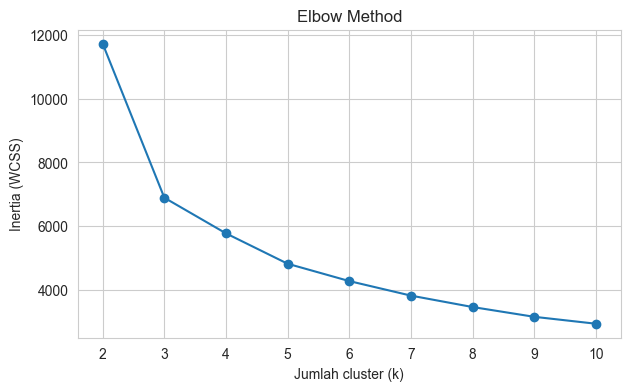

Elbow (metode jarak ke garis) pada k = 4


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(list(K_RANGE), inertias, marker="o")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method")
plt.xticks(list(K_RANGE))
plt.show()

ks = np.array(list(K_RANGE), dtype=float)
y = np.array(inertias)
p1, p2 = np.array([ks[0], y[0]]), np.array([ks[-1], y[-1]])
v = p2 - p1
d = [abs(v[0] * (b - p1[1]) - v[1] * (a - p1[0])) / np.linalg.norm(v) for a, b in zip(ks, y)]
print("kneed tidak terpasang. Elbow (metode jarak ke garis) pada k =", int(ks[int(np.argmax(d))]))

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [16]:
sil_scores = {}
for k in K_RANGE:
    lab = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(X_log_scaled)
    sil_scores[k] = silhouette_score(X_log_scaled, lab)
display(pd.Series(sil_scores, name="silhouette").round(4).to_frame())

,silhouette
2,0.5856
3,0.4630
4,0.3359
5,0.3564
6,0.3416
7,0.3375
8,0.3142
9,0.3290
10,0.3161


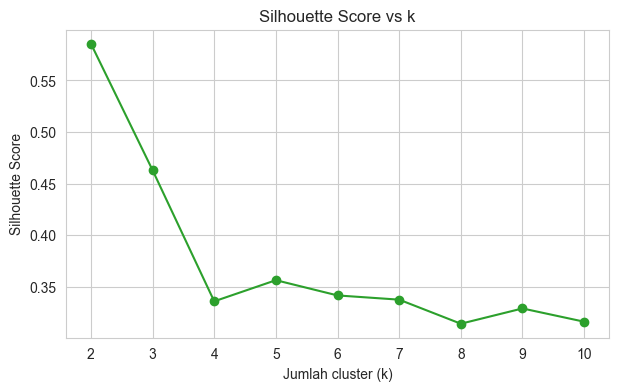

k terbaik menurut Silhouette: 2 | skor = 0.5856


In [17]:
plt.figure(figsize=(7, 4))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker="o", color="tab:green")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs k")
plt.xticks(list(K_RANGE))
plt.show()

best_k_sil = max(sil_scores, key=sil_scores.get)
print("k terbaik menurut Silhouette:", best_k_sil, "| skor =", round(sil_scores[best_k_sil], 4))

**Pilihan k untuk K-Means:** k = 3 .

Alasan: Elbow Method menunjukkan siku pada k kecil (sekitar 3), sedangkan Silhouette Score biasanya tertinggi pada k = 2 lalu menurun. k = 2 hanya memisahkan posting "sepi" dan "ramai" sehingga kurang informatif. k = 3 masih memiliki Silhouette yang tinggi dan sejalan dengan siku pada grafik Elbow, serta menghasilkan segmentasi yang lebih bermakna (misalnya posting biasa, posting dengan banyak diskusi/komentar, dan posting viral/banyak share).

## 3.4 Model K-Means Final

In [ ]:
K_FINAL = 3  

kmeans_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=N_INIT)
labels_km = kmeans_final.fit_predict(X_log_scaled)
print("Ukuran cluster K-Means:", dict(pd.Series(labels_km).value_counts().sort_index()))
print("Silhouette:", round(silhouette_score(X_log_scaled, labels_km), 4))

Ukuran cluster K-Means: {0: np.int64(3640), 1: np.int64(1135), 2: np.int64(2275)}
Silhouette: 0.463


In [19]:
def profile_clusters(labels, name="cluster"):
    d = X_raw.copy()
    d[name] = labels
    g = d.groupby(name)
    out = pd.concat([g.median().add_suffix("_median"), g.mean().add_suffix("_mean")], axis=1)
    out.insert(0, "n_anggota", g.size())
    out.insert(1, "persen", (g.size() / len(d) * 100).round(2))
    return out.round(2)

profile_km = profile_clusters(labels_km, "cluster_km")
display(profile_km)

,n_anggota,persen,num_likes_median,num_comments_median,num_shares_median,num_emoji_median,num_likes_mean,num_comments_mean,num_shares_mean,num_emoji_mean
cluster_km,,,,,,,,,,
0,3640,51.63,18.0,0.0,0.0,0.0,22.70,2.13,0.55,0.24
1,1135,16.10,171.0,715.0,176.0,57.0,316.31,1331.07,237.31,83.12
2,2275,32.27,211.0,11.0,1.0,2.0,472.27,27.78,4.76,4.85


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [20]:
Z = linkage(X_log_scaled, method="ward")
print("Bentuk linkage matrix:", Z.shape)

Bentuk linkage matrix: (7049, 4)


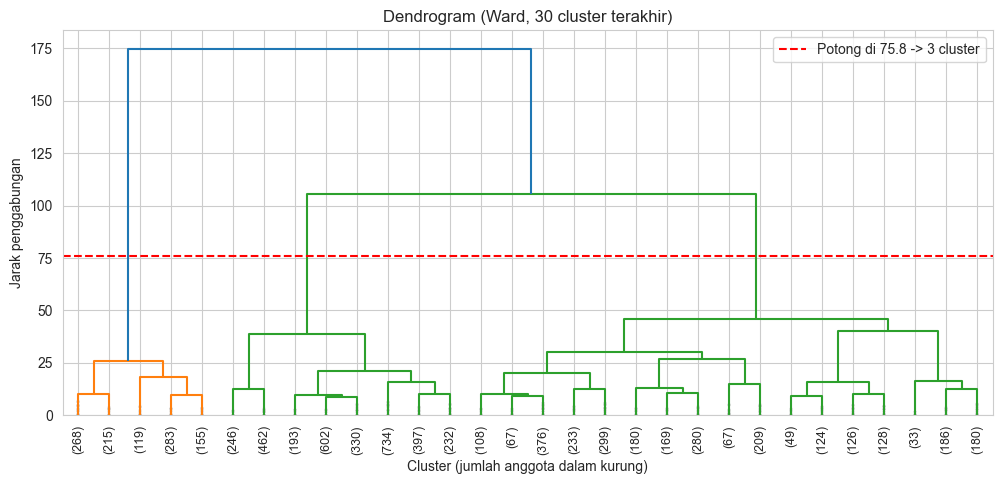

Lima loncatan jarak penggabungan terakhir: [ 38.94  40.18  46.07 105.47 174.75]


In [21]:
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)

# Tinggi potong yang menghasilkan K_FINAL cluster
cut_height = (Z[-(K_FINAL - 1), 2] + Z[-K_FINAL, 2]) / 2
plt.axhline(cut_height, color="red", linestyle="--", label=f"Potong di {cut_height:.1f} -> {K_FINAL} cluster")
plt.title("Dendrogram (Ward, 30 cluster terakhir)")
plt.xlabel("Cluster (jumlah anggota dalam kurung)")
plt.ylabel("Jarak penggabungan")
plt.legend()
plt.show()

print("Lima loncatan jarak penggabungan terakhir:", np.round(Z[-5:, 2], 2))

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [22]:
linkages = ["ward", "complete", "average", "single"]
labels_link = {}
for lk in linkages:
    agg = AgglomerativeClustering(n_clusters=K_FINAL, linkage=lk)
    labels_link[lk] = agg.fit_predict(X_log_scaled)
    print(f"{lk:9s} selesai")

ward      selesai
complete  selesai
average   selesai
single    selesai


In [23]:
rows = []
for lk, lab in labels_link.items():
    sizes = pd.Series(lab).value_counts().sort_index().tolist()
    rows.append({
        "Linkage": lk,
        "Silhouette": round(silhouette_score(X_log_scaled, lab), 4),
        "Ukuran cluster": sizes,
        "Cluster terkecil": min(sizes),
        "Cluster terbesar": max(sizes),
    })
link_table = pd.DataFrame(rows)
display(link_table)

,Linkage,Silhouette,Ukuran cluster,Cluster terkecil,Cluster terbesar
0,ward,0.4258,"[2814, 1040, 3196]",1040,3196
1,complete,0.4379,"[2406, 1017, 3627]",1017,3627
2,average,0.4964,"[1084, 5931, 35]",35,5931
3,single,0.3122,"[7048, 1, 1]",1,7048


**Pilihan linkage untuk Hierarchical Clustering:** ward .

Alasan: Ward meminimalkan kenaikan varians dalam cluster sehingga menghasilkan cluster yang kompak dan ukurannya relatif seimbang, serta konsisten dengan tujuan K-Means (meminimalkan WCSS) pada ruang Euclidean yang sudah di-scaling. Single linkage cenderung membentuk satu cluster raksasa dan cluster-cluster kecil berisi beberapa titik (efek chaining) sehingga kurang berguna untuk segmentasi, sedangkan complete dan average biasanya berada di antaranya.

## 4.3 Model Hierarchical Clustering Final

In [ ]:
LINKAGE_FINAL = "ward"  

hc_final = AgglomerativeClustering(n_clusters=K_FINAL, linkage=LINKAGE_FINAL)
labels_hc = hc_final.fit_predict(X_log_scaled)
print("Ukuran cluster HC:", dict(pd.Series(labels_hc).value_counts().sort_index()))
print("Silhouette:", round(silhouette_score(X_log_scaled, labels_hc), 4))

Ukuran cluster HC: {0: np.int64(2814), 1: np.int64(1040), 2: np.int64(3196)}
Silhouette: 0.4258


In [25]:
profile_hc = profile_clusters(labels_hc, "cluster_hc")
display(profile_hc)

,n_anggota,persen,num_likes_median,num_comments_median,num_shares_median,num_emoji_median,num_likes_mean,num_comments_mean,num_shares_mean,num_emoji_mean
cluster_hc,,,,,,,,,,
0,2814,39.91,167.0,10.0,1.0,1.0,415.87,31.24,5.48,4.95
1,1040,14.75,168.0,815.5,193.5,60.5,277.53,1430.19,255.40,88.24
2,3196,45.33,15.0,0.0,0.0,0.0,17.89,2.00,0.35,0.17


# 5. Evaluasi Model

In [26]:
results = {}
for name, lab in {"K-Means": labels_km, f"Hierarchical ({LINKAGE_FINAL})": labels_hc}.items():
    results[name] = {
        "Silhouette (tinggi=baik)": silhouette_score(X_log_scaled, lab),
        "Davies-Bouldin (rendah=baik)": davies_bouldin_score(X_log_scaled, lab),
        "Calinski-Harabasz (tinggi=baik)": calinski_harabasz_score(X_log_scaled, lab),
    }
metrics_table = pd.DataFrame(results).T.round(4)
display(metrics_table)

,Silhouette (tinggi=baik),Davies-Bouldin (rendah=baik),Calinski-Harabasz (tinggi=baik)
K-Means,0.4630,0.8315,10891.4081
Hierarchical (ward),0.4258,0.8383,9958.1158


Varians dijelaskan: PC1 = 75.90%, PC2 = 15.87%, total = 91.78%


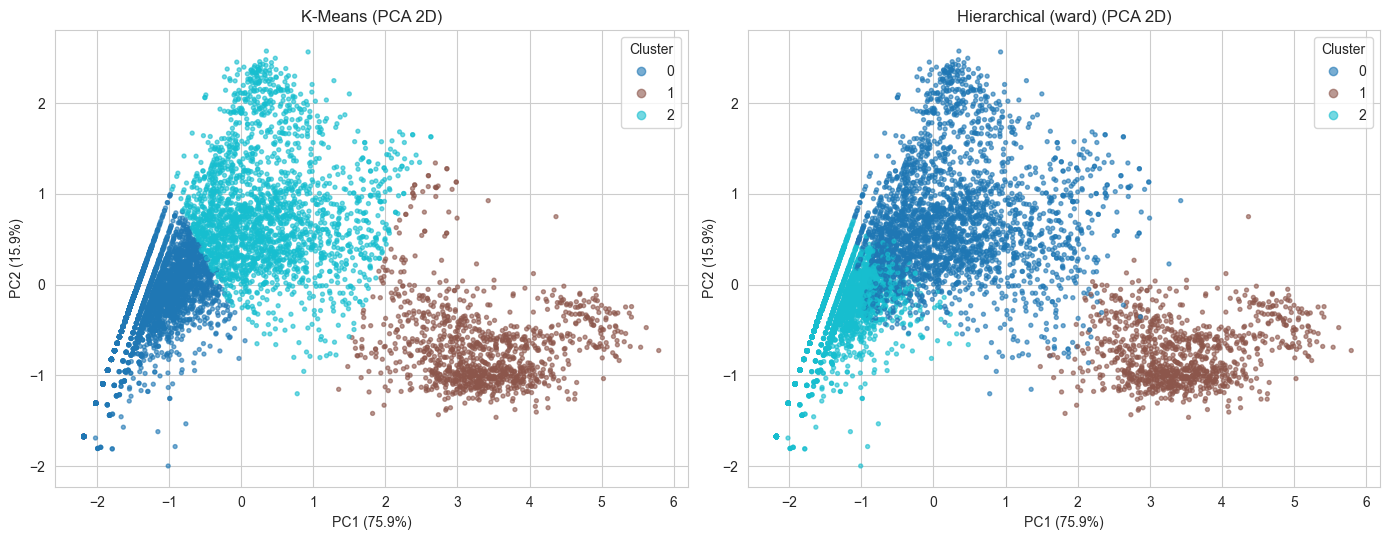

In [27]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_log_scaled)
ev = pca.explained_variance_ratio_ * 100
print(f"Varians dijelaskan: PC1 = {ev[0]:.2f}%, PC2 = {ev[1]:.2f}%, total = {ev.sum():.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, lab, title in zip(axes, [labels_km, labels_hc], ["K-Means", f"Hierarchical ({LINKAGE_FINAL})"]):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=lab, cmap="tab10", s=8, alpha=0.6)
    ax.set_title(f"{title} (PCA 2D)")
    ax.set_xlabel(f"PC1 ({ev[0]:.1f}%)")
    ax.set_ylabel(f"PC2 ({ev[1]:.1f}%)")
    ax.legend(*sc.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()

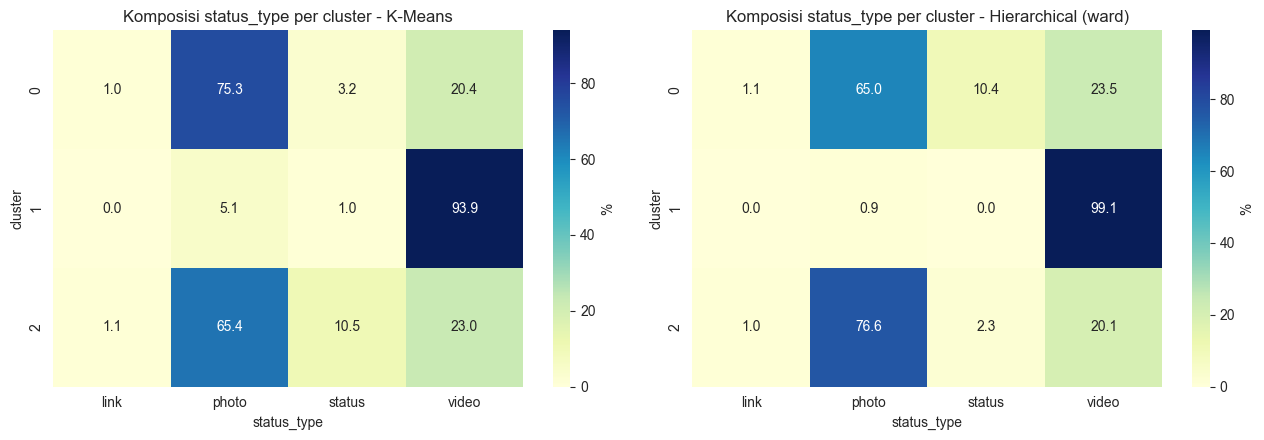

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, lab, title in zip(axes, [labels_km, labels_hc], ["K-Means", f"Hierarchical ({LINKAGE_FINAL})"]):
    ct = pd.crosstab(pd.Series(lab, name="cluster"), meta["status_type"], normalize="index") * 100
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "%"})
    ax.set_title(f"Komposisi status_type per cluster - {title}")
plt.tight_layout()
plt.show()

# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.


---

### Jawaban Analisis


1. Pengaruh transformasi log dan scaling pada K-Means (bagian 3.1).
Tanpa scaling, fitur dengan skala terbesar (biasanya num_likes, lalu num_comments/num_shares) mendominasi hampir seluruh varians sehingga jarak Euclidean praktis hanya ditentukan oleh satu-dua fitur. Data juga sangat miring dan memiliki outlier ekstrem (posting viral), sehingga K-Means pada data mentah cenderung menghasilkan satu cluster yang sangat besar dan cluster lain yang sangat kecil berisi outlier, serta centroid tertarik oleh outlier. Scaling menyamakan kontribusi tiap fitur, sedangkan log1p menekan ekor panjang dan memperkecil pengaruh outlier. Kombinasi keduanya (X_log_scaled) menghasilkan cluster yang lebih seimbang dan bermakna . Keduanya penting karena K-Means dan Hierarchical Clustering sepenuhnya bergantung pada jarak.

2. Penanganan kolom redundan dan sparse.
num_reactions dibuang karena merupakan penjumlahan reaksi lain (redundan). Lima reaksi emoji sebagian besar bernilai nol, sehingga digabung menjadi num_emoji. Fitur akhir: num_likes, num_comments, num_shares, num_emoji. Outlier tidak dibuang karena mewakili posting viral yang memang ingin dikelompokkan, dampaknya diredam oleh transformasi log.

3. Jumlah cluster optimal.
Elbow Method menunjukkan siku pada k sekitar 3 , sedangkan Silhouette Score cenderung tertinggi pada k = 2 . Keduanya tidak selalu sama: Elbow bersifat subjektif dan menilai kompaksi, Silhouette menilai pemisahan antar cluster. k = 2 hanya membedakan posting sepi dan ramai, jadi dipilih k = 3 sebagai kompromi antara skor dan interpretabilitas.

4. Perbandingan linkage.
Ward dan (umumnya) complete menghasilkan cluster yang lebih seimbang, average berada di antaranya, single linkage cenderung menghasilkan satu cluster sangat besar dan cluster kecil berisi sedikit titik karena efek *chaining* (titik-titik terhubung berantai lewat tetangga terdekat), sehingga tidak berguna untuk segmentasi meski Silhouette-nya bisa terlihat tinggi. Ward dipilih karena kompak, seimbang, dan selaras dengan tujuan varians minimum.

5. K-Means vs Hierarchical.
Dengan fitur dan jumlah cluster yang sama, kedua metode biasanya menghasilkan metrik internal (Silhouette, Davies-Bouldin, Calinski-Harabasz) dan pola PCA yang mirip , karena Ward dan K-Means sama-sama meminimalkan varians dalam cluster dan struktur data yang terbentuk cukup jelas setelah log + scaling. Perbedaan kecil muncul di batas antar cluster, dan K-Means umumnya sedikit unggul pada Calinski-Harabasz karena secara eksplisit mengoptimalkan WCSS. Perlu diingat PCA 2D hanya menampilkan sebagian varians , sehingga tumpang tindih visual tidak selalu berarti cluster buruk.

6. Karakteristik dan julukan cluster.
Berdasarkan profil median dan komposisi status_type : (a) Posting Sepi: median likes, komentar, share rendah, banyak berupa foto/status, (b) Posting Diskusi: komentar dan emoji relatif tinggi tetapi share rendah, (c) Posting Viral Video: engagement dan share tinggi, didominasi video. Julukan akhir harus mengikuti angka median pada tabel profil Anda.

7. Kelebihan dan kekurangan.
- K-Means: cepat dan hemat memori (kompleksitas sekitar O(n·k·i)), mudah diskalakan, namun harus menentukan k di awal, sensitif terhadap inisialisasi dan outlier, serta mengasumsikan cluster berbentuk bulat dengan ukuran serupa.
- Hierarchical: tidak perlu menentukan k di awal (dendrogram membantu memilih), mampu menangkap hierarki dan (dengan linkage tertentu) bentuk non-bulat, namun membutuhkan waktu O(n²) hingga O(n³) dan memori O(n²) sehingga sulit untuk data besar, serta keputusan penggabungan tidak bisa dibatalkan, dan hasilnya sangat bergantung pada pemilihan linkage.

# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.


---

### Kesimpulan

1. Transformasi log1p dan scaling sangat penting; tanpa keduanya clustering didominasi satu fitur dan outlier sehingga cluster menjadi tidak seimbang.
2. Fitur yang dipakai adalah num_likes, num_comments, num_shares, dan num_emoji (gabungan reaksi emoji yang sparse); num_reactions dibuang karena redundan.
3. Jumlah cluster yang dipilih adalah k = 3 *(sesuaikan dengan output)*, berdasarkan Elbow Method dan Silhouette Score.
4. Ward linkage memberikan cluster paling seimbang, sedangkan single linkage menunjukkan efek chaining.
5. K-Means dan Hierarchical (Ward) memberikan hasil yang mirip pada metrik internal dan visualisasi PCA; K-Means lebih efisien untuk data besar, Hierarchical memberi gambaran hierarki lewat dendrogram.
6. Cluster dapat dimaknai sebagai tingkat engagement posting (sepi, diskusi, viral) dan berkaitan dengan status_type.

### Saran

- Lakukan clustering terpisah untuk periode sebelum dan sesudah 2016 karena reaksi emoji baru tersedia setelahnya.
- Tambahkan fitur waktu (jam dan hari posting) dan status_type hasil encoding sebagai analisis lanjutan.
- Coba DBSCAN atau Gaussian Mixture Model untuk cluster non-bulat dan outlier.
- Coba reduksi dimensi sebelum clustering dan variasi n_init/init (misalnya k-means++) pada K-Means.